In [1]:
from roentgen.absorption import Material
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from specutils import Spectrum1D
from astropy.visualization import quantity_support
import numpy as np
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x218d1e50be0>

In [5]:
number_of_detectors = 4
geo_area_detector = 0.81 * u.cm ** 2
meddea_geo_area = number_of_detectors * geo_area_detector

# caliste so properties see https://github.com/i4Ds/STIXCore/blob/master/stixcore/calibration/transmission.py#L18
detector_thickness = 1 * u.mm
det_cathode = Material("Pt", 30 * u.nm)

Load x-class flare data

In [6]:
xclass_spec_file = 'SOL2002-07-23_RHESSI_flare_spectrum.csv'
flare_data = pd.read_csv(xclass_spec_file, index_col=3)
flare_energy = u.Quantity(flare_data.index, 'keV')
flux = u.Quantity(flare_data['Flux (photons/s/cm2/keV)'], 'ph s ** (-1) cm**(-2) keV**(-1)')
flare_spec = Spectrum1D(spectral_axis=flare_energy.to('Hz', equivalencies=u.spectral()), flux=flux)

Text(0.5, 1.0, 'SOL2002-07-23 X4.8 power-law index 2.77')

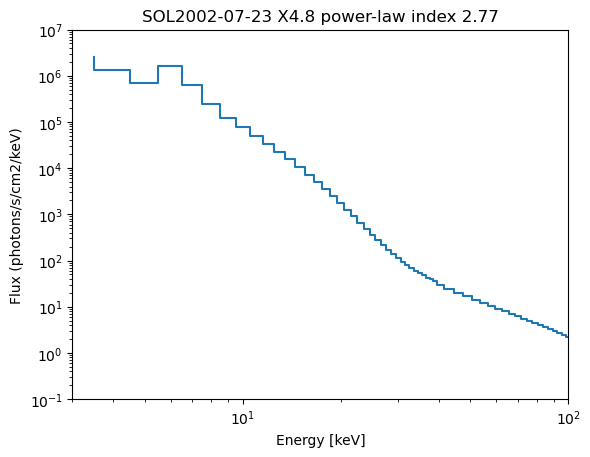

In [7]:
plt.step(flare_spec.energy.to('keV'), flare_spec.flux)
plt.yscale('log')
plt.xscale('log')
plt.xlim(3, 100)
plt.ylim(1e-1, 1e7)
plt.xlabel('Energy [keV]')
plt.ylabel('Flux (photons/s/cm2/keV)')
plt.title("SOL2002-07-23 X4.8 power-law index 2.77")

In [30]:
i = 26
print(f"{flare_spec.energy.to('keV')[i]}, {flare_spec.flux[i] / 10. / 2.}")

29.5 keV, 6.8805499999999995 ph / (keV s cm2)


In [8]:
det_cathode = Material("Pt", 30 * u.nm)
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
# MLI blankets
MIL_SI = 0.0254 * u.mm
mli_parts = [('al', 1000 * u.angstrom), ('C', 3 * MIL_SI), ('al', 40 * 1000 * u.angstrom),
             ('C', 20 * 0.25 * MIL_SI), ('C', 3 * MIL_SI),
             ('al', 1000 * u.angstrom)]
blankets = Material('C', (3 + 20 * 0.05 + 3) * MIL_SI)
optical_path_no_filters = (blankets).transmission(flare_energy)

no filters low energy effective area 3.07 cm2 cm^2, high energy effective area 3.03 cm2 cm^2
1mm-Be 0.4mm-Al low energy effective area 1.53 cm2 cm^2, high energy effective area 2.83 cm2 cm^2
3 detectors low energy effective area 1.15 cm2 cm^2, high energy effective area 2.12 cm2 cm^2


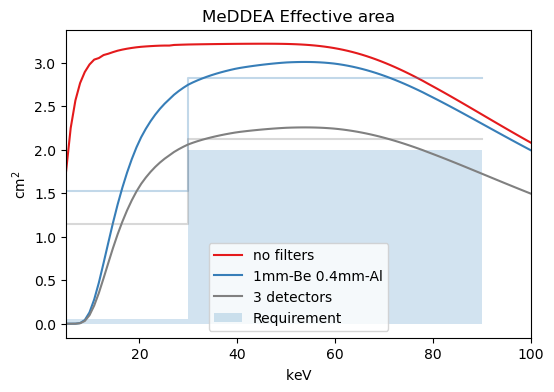

In [ ]:
import matplotlib as mpl
name = "Set1"
cmap = mpl.colormaps[name]
colors = [cmap.colors[0], cmap.colors[1], 'grey']

energy = np.linspace(5, 100, 100) * u.keV
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(energy) * det_cathode.transmission(energy)
detector_area = meddea_geo_area * detector_efficiency
optical_path_0 = blankets
optical_path_1 = blankets + Material("Be", thickness=1 * u.mm) + Material("Al", thickness=0.4 * u.mm)
label = ['no filters', '1mm-Be 0.4mm-Al', '3 detectors']

low_erange = [5, 30] * u.keV
hi_erange = [30, 90] * u.keV

plt.figure(figsize=(6, 4))
ax0=plt.subplot(1, 1, 1)
eff_area = [detector_area * optical_path_0.transmission(energy),
            detector_area * optical_path_1.transmission(energy),
            detector_area * optical_path_1.transmission(energy) * 3/4.]

for this_color, this_label, this_eff_area in zip(colors, label, eff_area):
    eindex = (energy > low_erange[0]) * (energy < low_erange[1])
    low_eff_area_avg = np.mean(this_eff_area[eindex])
    eindex = (energy > hi_erange[0]) * (energy < hi_erange[1])
    high_eff_area_avg = np.mean(this_eff_area[eindex])
    ax0.plot(energy, this_eff_area, label=this_label, color=this_color)
    print(f"{this_label} low energy effective area {low_eff_area_avg:.2f} cm^2, high energy effective area {high_eff_area_avg:.2f} cm^2")
    if this_label != 'no filters':
        ax0.plot(u.Quantity([low_erange[0], low_erange[1], hi_erange[0], hi_erange[1]]),
                 u.Quantity([low_eff_area_avg, low_eff_area_avg, high_eff_area_avg, high_eff_area_avg]),
                 color=this_color, alpha=0.3)

ax0.set_xlim(5, 100)
ax0.set_title('MeDDEA Effective area')
ax0.fill_between((5, 30, 30, 90), (0.05, 0.05, 2, 2), alpha= 0.2, label='Requirement')
ax0.legend()
plt.savefig('effective_area.pdf')

minimum flare energy 3.5 keV keV, maximum flare energy 14950.0 keV keV
count rate at energy 29.5 keV keV: 28 cts/s,  1,691 cts/min


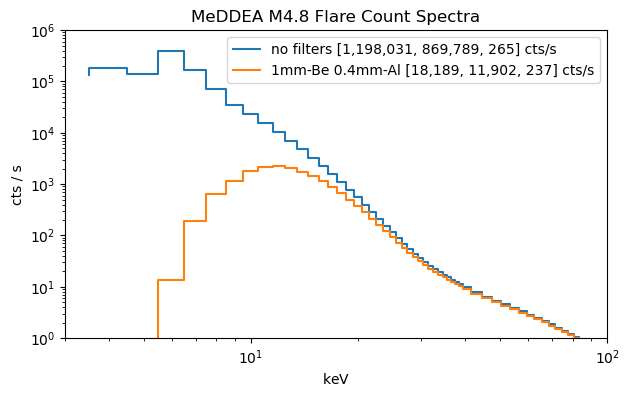

In [45]:
plt.figure(figsize=(7, 4))
ax1=plt.subplot(1, 1, 1)
print(f"minimum flare energy {flare_spec.energy.to('keV').min():.1f} keV, maximum flare energy {flare_spec.energy.to('keV').max():.1f} keV")
flare_energy = flare_spec.energy.to('keV')
detector_efficiency = Material('cdte', thickness=detector_thickness).absorption(flare_energy) * det_cathode.transmission(flare_energy)
detector_area = meddea_geo_area * detector_efficiency
eff_area_flare = [detector_area * optical_path_0.transmission(flare_energy),
            detector_area * optical_path_1.transmission(flare_energy),
            detector_area * optical_path_1.transmission(flare_energy) * 3/4.]

for this_color, this_label, this_eff_area in zip(colors, label, eff_area_flare):
    mflare_count_spectrum = flare_spec.flux * this_eff_area / 10.0
    total_rate = mflare_count_spectrum.sum().value
    total_thermal = mflare_count_spectrum[(flare_energy.value >= 5) * (flare_energy.value <= 15)].sum().value
    total_nonthermal = mflare_count_spectrum[(flare_energy.value > 30)].sum().value
    if this_label != '3 detectors':
        ax1.step(flare_energy, mflare_count_spectrum, label=f'{this_label} [{total_rate:,.0f}, {total_thermal:,.0f}, {total_nonthermal:,.0f}] cts/s')

i = 26
print(f"count rate at energy {flare_energy[i]:.1f} keV: {mflare_count_spectrum[i].value:,.0f} cts/s,  {mflare_count_spectrum[i].value * 60:,.0f} cts/min")

#ax1.axvspan(10, 60, alpha=0.2, color='grey')
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylabel('cts / s')
ax1.set_xlim(3, 100)
ax1.set_ylim(1, 1e6)
ax1.set_title('MeDDEA M4.8 Flare Count Spectra')
ax1.legend()
plt.savefig('Mflare_spectrum.pdf')